# Module I: Neural networks, MLP, backpropagation, MNIST
A multilayer perceptron written **from scratch in NumPy** (manual forward pass and backpropagation), then reused as the baseline for partial sketches.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, inspect
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda m: json.load(open(ROOT / "runs" / m / "results.json"))
from src.models.mlp_numpy import MLP
print(inspect.getsource(MLP.step))

    def step(self, x, y):
        acts = self.forward(x)
        p = self.softmax(acts[-1])
        n = len(x)
        loss = -np.log(p[np.arange(n), y] + 1e-9).mean()
        delta = p
        delta[np.arange(n), y] -= 1.0
        delta /= n                                         # dL/dz_last
        for i in reversed(range(len(self.W))):
            gW = acts[i].T @ delta + self.l2 * self.W[i]
            gb = delta.sum(0)
            if i > 0:
                delta = (delta @ self.W[i].T) * (acts[i] > 0)   # ReLU derivative
            self.vW[i] = self.mom * self.vW[i] - self.lr * gW
            self.vb[i] = self.mom * self.vb[i] - self.lr * gb
            self.W[i] += self.vW[i]
            self.b[i] += self.vb[i]
        return float(loss)



## Backpropagation check
The analytic gradient from `step` must match a numerical (finite-difference) gradient.

In [2]:
rng = np.random.default_rng(0)
x = rng.random((16, 20)).astype('float32'); y = rng.integers(0, 5, 16)
net = MLP([20, 12, 8, 5], seed=1)
a, n = net.grad_check(x, y, eps=1e-2)
print('analytic', np.round(a, 5)); print('numeric ', np.round(n, 5)); print('max abs diff', float(np.abs(a - n).max()))

analytic [0.01807 0.      0.      0.02413 0.06443]
numeric  [0.01807 0.      0.      0.02413 0.06567]
max abs diff 0.0012336820363998413


## Digit classification on MNIST
A short training run here (3 epochs); the full 12-epoch run result is shown below it.

In [3]:
import torchvision
ds = torchvision.datasets.MNIST(ROOT / 'data' / 'processed' / 'mnist', train=True, download=True)
ts = torchvision.datasets.MNIST(ROOT / 'data' / 'processed' / 'mnist', train=False, download=True)
X = ds.data.numpy().reshape(-1, 784).astype('float32') / 255; Y = ds.targets.numpy()
Xt = ts.data.numpy().reshape(-1, 784).astype('float32') / 255; Yt = ts.targets.numpy()
net = MLP([784, 256, 128, 10], lr=0.05)
net.fit(X, Y, epochs=3, on_epoch=lambda e, l: print(f'epoch {e} loss {l:.4f} test acc {net.accuracy(Xt, Yt):.4f}'))

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<01:21, 121kB/s]

  1%|          | 65.5k/9.91M [00:00<01:21, 120kB/s]

  2%|▏         | 164k/9.91M [00:00<00:42, 230kB/s] 

  3%|▎         | 295k/9.91M [00:01<00:29, 326kB/s]

  6%|▌         | 557k/9.91M [00:01<00:17, 546kB/s]

... (22 outputs left out)

100%|██████████| 4.54k/4.54k [00:00<00:00, 1.29MB/s]

epoch 1 loss 0.2671 test acc 0.9616


epoch 2 loss 0.1022 test acc 0.9706


epoch 3 loss 0.0680 test acc 0.9734


In [4]:
print('Full run (12 epochs, Kaggle):', res('mlp_mnist'))

Full run (12 epochs, Kaggle): {'test_acc': 0.9785}


## Same network on partial sketches (baseline)
A 1024-512-256-30 MLP on 32x32 rasters of partial QuickDraw sketches.

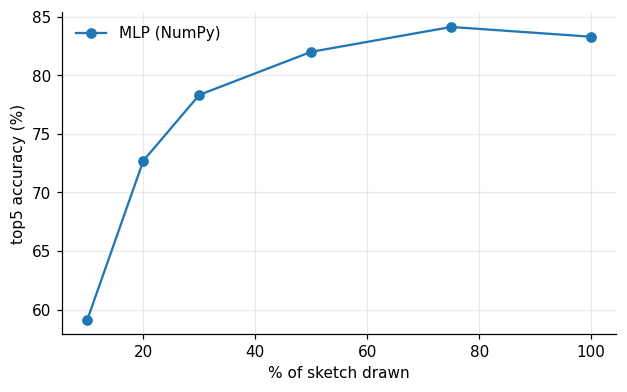

{'0.1': 0.591, '0.2': 0.727, '0.3': 0.783, '0.5': 0.82, '0.75': 0.841, '1.0': 0.833} (top-5)


In [5]:
def curve(models, metric="top5"):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for m, label in models.items():
        r = res(m); xs = sorted(r, key=float)
        ax.plot([float(x) * 100 for x in xs], [r[x][metric] * 100 for x in xs], marker="o", label=label)
    ax.set(xlabel="% of sketch drawn", ylabel=f"{metric} accuracy (%)"); ax.grid(alpha=.25); ax.legend(frameon=False); plt.show()
curve({'mlp': 'MLP (NumPy)'})
r = res('mlp'); print({k: round(v['top5'], 3) for k, v in r.items()}, '(top-5)')